# Image Cell Counting

In [1]:
import torch
assert torch.cuda.is_available(), "GPU not available" #this will give an error if no GPU available 

In [2]:
!pip install roboflow
!pip install ultralytics

In [ ]:
from google.colab import userdata
from roboflow import Roboflow
import os
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import cv2
from getpass import getpass
from ultralytics import YOLO
from IPython.display import Image

In [4]:
# api_key = userdata.get("ROBOFLOW_API_KEY") #for Google colab UI
api_key = getpass("Roboflow API key: ") #for Google colab implementation in VS code 

In [5]:
rf = Roboflow(api_key=api_key) # *---- Add api key to secrect w name ROBOFLOW_API_KEY ----*
project = rf.workspace("pranjal-singh-evqc5").project(
    "cell-counting-zeqo5-raras"  # *-------- Need to change this to specific dir --------*
)

version = project.version(1) #version generated on roboflow universe
dataset = version.download("yolo26") #chose this format for PyTorch compatibality

loading Roboflow workspace...
loading Roboflow project...


In [6]:
print(os.listdir(dataset.location))
assert "data.yaml" in os.listdir(dataset.location), "Incorrect data format, download as yolo"

['data.yaml', 'README.roboflow.txt', 'valid', 'test', 'train']


In [7]:
model = YOLO("yolo26n.pt")
results = model.train(data=f"{dataset.location}/data.yaml", epochs=100, imgsz=640, single_cls=True)

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cell-counting-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False,

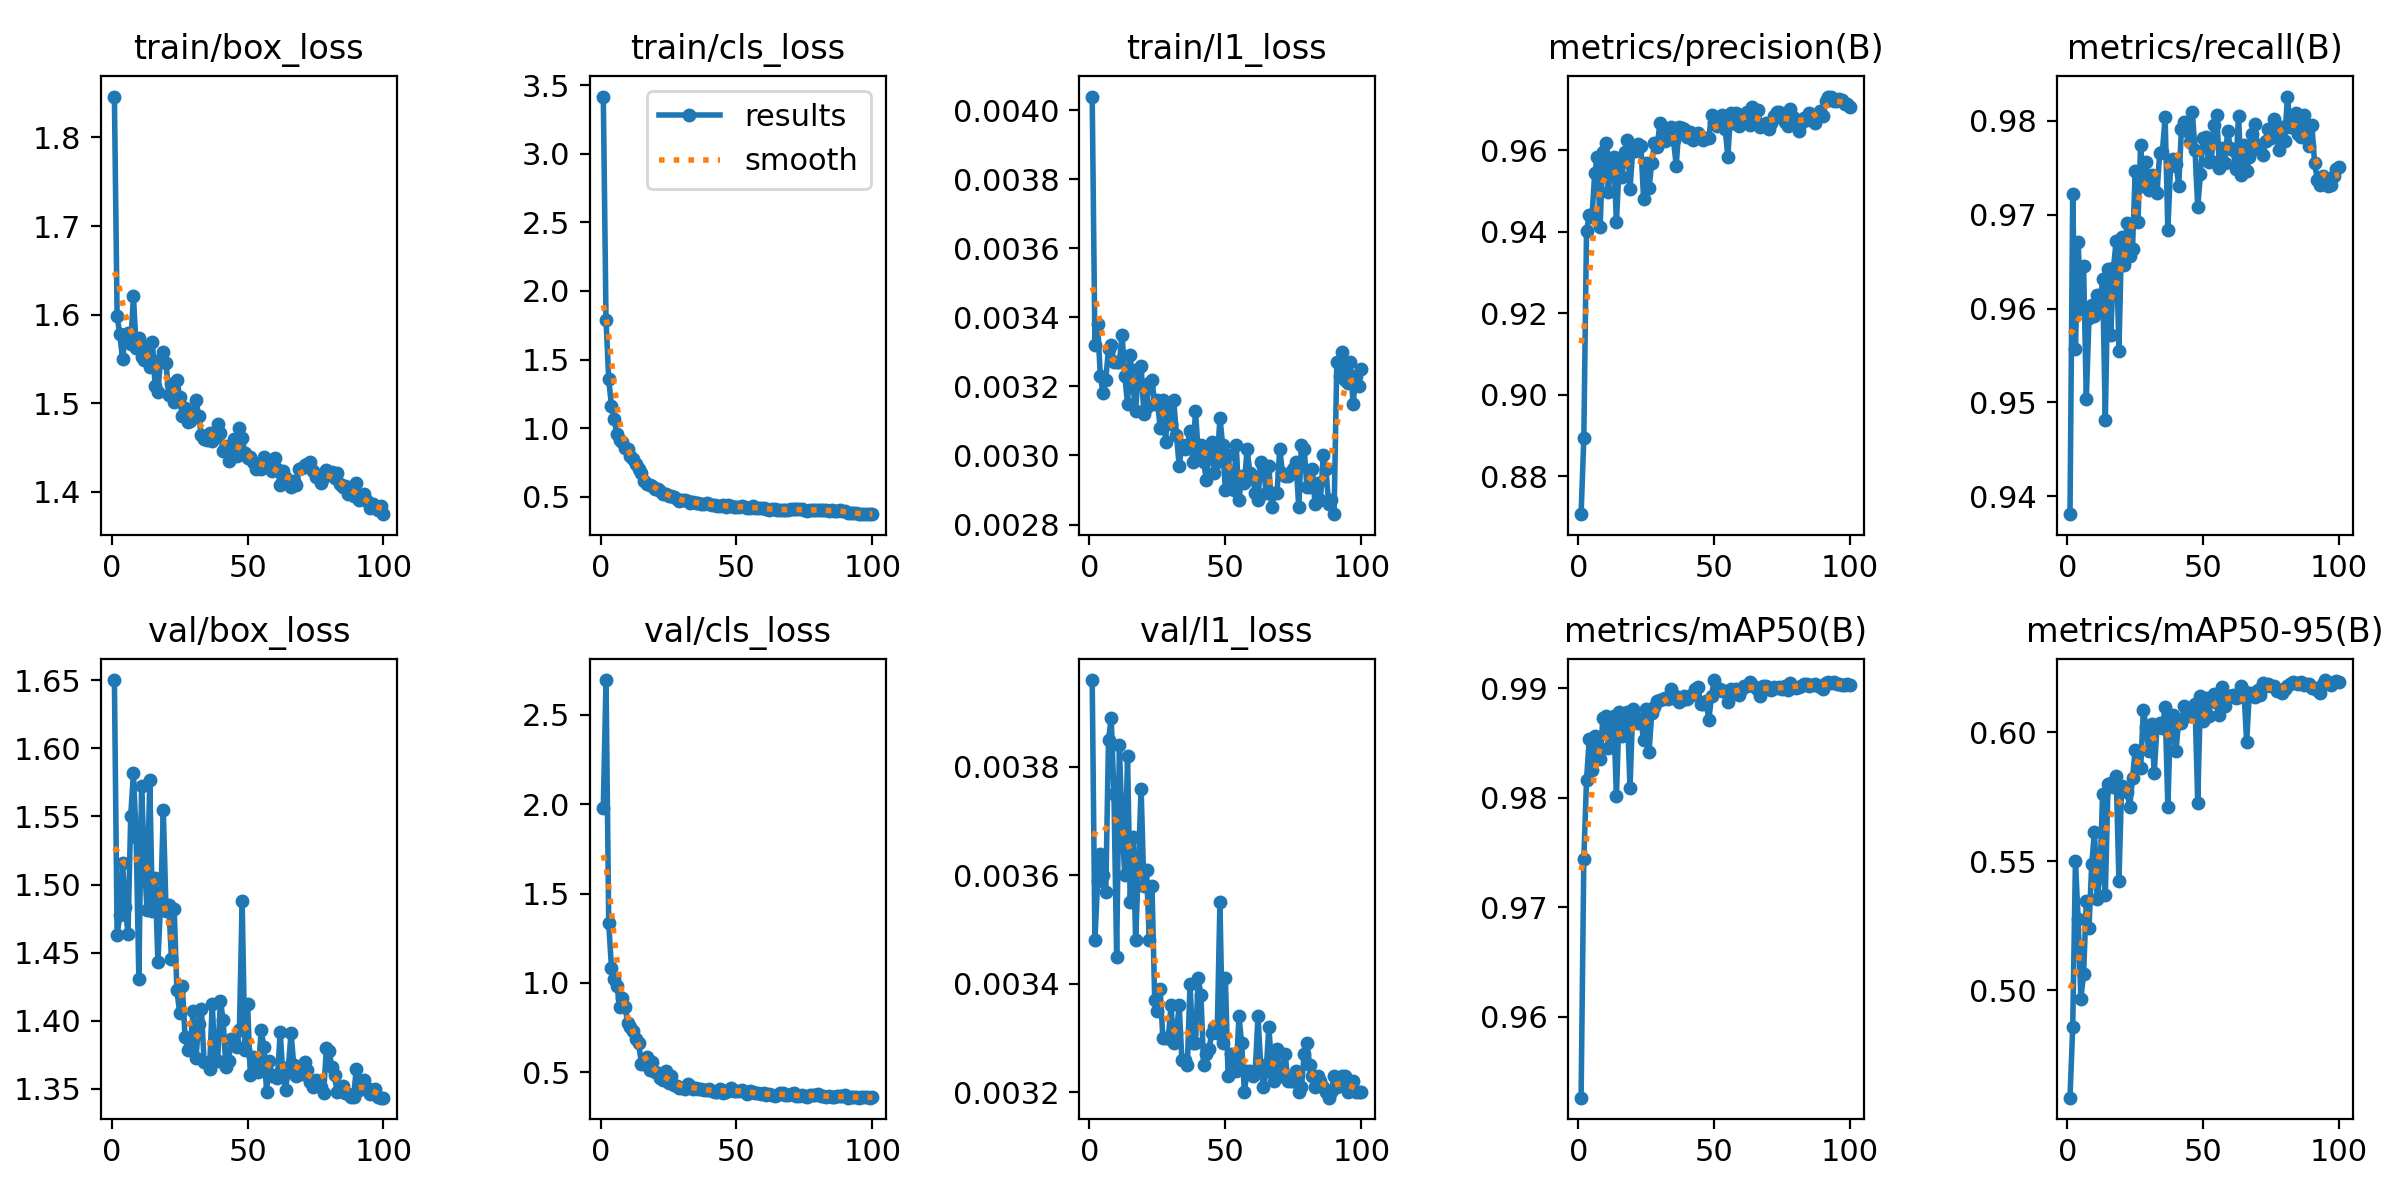

In [ ]:
Image(f"{results.save_dir}/results.png")